##### <img src=../figures/Brown_logo.svg width=50%>

## Data-Driven Design & Analyses of Structures & Materials (3dasm)

## Lecture 20

### Martin van der Schelling | <a href = "mailto: m.p.vanderschelling@tudelft.nl">m.p.vanderschelling@tudelft.nl</a>  | Doctoral Candidate

### Miguel A. Bessa | <a href = "mailto: miguel_bessa@brown.edu">miguel_bessa@brown.edu</a>  | Associate Professor

### Elvis Aguero | <a href = "mailto: elvis_vera@brown.edu">elvis_vera@brown.edu</a>  | PhD candidate

**What:** A lecture of the "3dasm" course

**Where:** This notebook comes from this [repository](https://github.com/bessagroup/3dasm_course)

**Reference for entire course:** Murphy, Kevin P. *Probabilistic machine learning: an introduction*. MIT press, 2022. Available online [here](https://probml.github.io/pml-book/book1.html)

**How:** We try to follow Murphy's book closely, but the sequence of Chapters and Sections is different. The intention is to use notebooks as an introduction to the topic and Murphy's book as a resource.
* If working offline: Go through this notebook and read the book.
* If attending class in person: listen to me (!) but also go through the notebook in your laptop at the same time. Read the book.
* If attending lectures remotely: listen to me (!) via Zoom and (ideally) use two screens where you have the notebook open in 1 screen and you see the lectures on the other. Read the book.

**References/resources to create this notebook:**
* [Car figure](https://korkortonline.se/en/theory/reaction-braking-stopping/)
* [`adda` documentation](https://bessagroup.github.io/adda/)

Apologies in advance if I missed some reference used in this notebook. Please contact me if that is the case, and I will gladly include it here.

## **OPTION 1**. Run this notebook **locally in your computer**:
1. Confirm that you have the '3dasm' mamba (or conda) environment (see Lecture 1).
2. Go to the 3dasm_course folder in your computer and pull the last updates of the [repository](https://github.com/bessagroup/3dasm_course):
```
git pull
```
    - Note: if you can't pull the repo due to conflicts (and you can't handle these conflicts), use this command (with **caution**!) and your repo becomes the same as the one online:
```
git reset --hard origin/main
```
3. Open command window and load jupyter notebook (it will open in your internet browser):
```
jupyter notebook
```
4. Open notebook of this Lecture and choose the '3dasm' kernel.

## **OPTION 2**. Use **Google's Colab** (no installation required, but times out if idle):

1. go to https://colab.research.google.com
2. login
3. File > Open notebook
4. click on Github (no need to login or authorize anything)
5. paste the git link: https://github.com/bessagroup/3dasm_course
6. click search and then click on the notebook for this Lecture.

Colab cannot run the agents of this notebook. You will see the recorded outputs, not new runs. To run a study yourself you need Option 1, with Claude Code installed (see Lecture 10).

In [1]:
# Basic plotting tools needed in Python.
import warnings; warnings.filterwarnings("ignore") # keeps the output of the notebook clean
import shutil, sys
from pathlib import Path
import matplotlib.pyplot as plt # import plotting tools to create figures
import numpy as np # import numpy to handle a lot of things!
import pandas as pd # to read the data
from IPython.display import SVG, Markdown, display
from sklearn.model_selection import train_test_split
from f3dasm import ExperimentData
from adda import Agent, Edge, Graph, AgenticRun, viewer

# adda switches off its machinery for long studies (a notebook as deliverable, its reproduction check, hypotheses...)
LEAN = dict(pipeline_deliverable=False, reproduction_gate=False, hypothesis_ledger=False,
            milestones_enabled=False, science_monitor=False, peer_interaction=False)

%config InlineBackend.figure_format = "retina" # render higher resolution images in the notebook
plt.rcParams["figure.figsize"] = (8,4) # rescale figure size appropriately for slides
pd.set_option('display.max_rows', 10) # To limit the number of rows to show in a dataframe, for presentation purposes

## Outline for today

* Decide before you prompt: the statement as a table of decisions
* A team of three agents: a coordinator, a builder and a checker
* Delegate or hand off: two ways to pass work
* Running work in parallel
* The limits of a run: time, cost, evaluations
* Running the same study twice

**Reading material**: This notebook + the [`adda` documentation](https://bessagroup.github.io/adda/).

## Last lecture

* A **study** is a folder with `PROBLEM_STATEMENT.md`.
* A **team** is a `Graph` of agents, each an `Agent(model, tools)`.
* Our own **tool** is a Python function listed in `tools`, and our record is an `ExperimentData`.

With `Measure`, the agent chose the speeds, the model of the standard deviation, and the fit. The statement fixed none of these choices, so another run may choose differently.

## Decide before you prompt

To compare models, or to reproduce a result, **we** make the choices, and the agents carry them out:

* the data and how it is split
* the models, written so that only one implementation is possible
* how each model is assessed
* the files to deliver, with their columns

The agents implement; they do not interpret. Then every number they return can be checked.

## The data: 50 stops

The stops of 50 drivers, as an `ExperimentData` (Lecture 18). The team gets a copy in its study folder.

In [2]:
stops = ExperimentData.from_file("../data/car_stopping_distance")
x_stops, y_stops = stops.to_pandas()
print("stops:", len(stops))
stops

stops: 50


,jobs,input,output
,,x,y
0,finished,3.00,5.231400
1,finished,43.00,277.273153
2,finished,63.00,462.585642
3,finished,23.00,75.836729
4,finished,33.00,144.306322
...,...,...,...
45,finished,71.75,654.692199
46,finished,51.75,323.810428
47,finished,11.75,44.202473


In [3]:
Path("car_team").mkdir(exist_ok=True)
shutil.copytree("../data/car_stopping_distance", "car_team/data/car_stopping_distance", dirs_exist_ok=True)

'car_team/data/car_stopping_distance'

## The statement is a table of decisions

Two models of the stopping distance, each written down to the last choice:

* **M1**: $y = a\,x + b\,x^2$, and a **constant** standard deviation $s$
* **M2**: $y = a\,x + b\,x^2$, and a standard deviation **proportional to the speed**, $c\,x$

Both are fitted on the same 37 training stops, and assessed on the other 13.

In [4]:
%%writefile car_team/PROBLEM_STATEMENT.md
# Two models of the stopping distance of a car

Data: `data/car_stopping_distance`, an f3dasm ExperimentData of 50 stops (input `x`, speed in m/s; output `y`,
stopping distance in m). Load it with `ExperimentData.from_file`, and take the tables with `to_pandas()`.

| Item | Decision |
|---|---|
| Split | `train_test_split(row index, train_size=0.75, random_state=1987)` from scikit-learn: 37 training rows, 13 test rows |
| M1 | `a, b` by `numpy.linalg.lstsq` of `y` on the columns `[x, x**2]` (no intercept), training rows. `s` = `numpy.std` of the training residuals (ddof=0). Mean `a*x + b*x**2`, standard deviation `s` |
| M2 | `a, b` by `numpy.linalg.lstsq` of `y/x` on the columns `[1, x]`, training rows. `c` = `numpy.std` of the residuals of `y/x` (ddof=0). Mean `a*x + b*x**2`, standard deviation `c*x` |
| Assessment | On the test rows: `coverage`, the fraction of `y` inside mean +- 1.96 standard deviation; `nll`, the mean of minus the log of the normal density of `y` |

## Deliverables (folder `workspace/results/`)

- `fit_M1.py` and `M1.csv`, `fit_M2.py` and `M2.csv`. Each CSV has one row and exactly the columns `model`, `a`, `b`,
  `sd_parameter` (`s` for M1, `c` for M2), `coverage`, `nll`, `n_train`, `n_test`.
- `check.md`

Overwriting car_team/PROBLEM_STATEMENT.md


**Note.** The deliverables go in `workspace/`, because `adda` lets each agent of a team write only in its own folder (`runs/<timestamp>/debug/delegations/D001/`, ...) and in the `workspace/` of the study, when the statement names a file there.

## A team of three agents

* The **coordinator** reads the statement and hands out the work. Its tools only read files, so it cannot write code itself.
* The **builder** has every tool of Claude Code. It writes and runs the code of one model.
* The **checker** has them too, and a **different job**. It recomputes the results without using the builder's code.

Each node has a `description`. The coordinator reads only these lines to decide whom to give each piece of work.

In [5]:
rules = (" Read PROBLEM_STATEMENT.md in the study folder first: it holds every decision. Do not change any of them."
         " Write your files in workspace/results/ only. Do the task yourself: do not start sub-agents."
         f" Run Python with {sys.executable}.") # the Python of this notebook, which has f3dasm

In [6]:
coordinator = Agent(
    model="haiku",
    description="Hands out the work and writes the final report.",
    system_prompt="You write no code. Delegate, with the full path of the study folder in each task:"
                  " (1) to builder for M1 and to builder for M2, at the same time (wait=False), then Wait for both;"
                  " (2) to checker (wait=True). End with a report (the two rows and the result of each check), then call Done." + rules,
    tools={"Read", "Glob", "Grep", "Wait", "FollowUp", "Done"}) # it reads files, waits, asks us, and closes the run

In [7]:
builder = Agent(
    model="haiku",
    tools={"Default"},
    description="Writes and runs the fit of one model.",
    system_prompt="Write workspace/results/fit_<model>.py for the model named in your task, exactly as stated in"
                  " PROBLEM_STATEMENT.md, run it, and report its row of results." + rules)

In [8]:
checker = Agent(
    model="haiku",
    tools={"Default"},
    description="Recomputes the results independently and reports PASS or FAIL.",
    system_prompt="Do not import or run the scripts in workspace/results/. Recompute yourself, from the data and the decisions:"
                  " (1) the numbers of training and test rows; (2) a, b and sd_parameter of M1 and M2;"
                  " (3) coverage and nll of both. Write in workspace/results/check.md PASS or FAIL for each item, with the numbers"
                  " of the CSV files and yours (relative difference below 1e-6)." + rules)

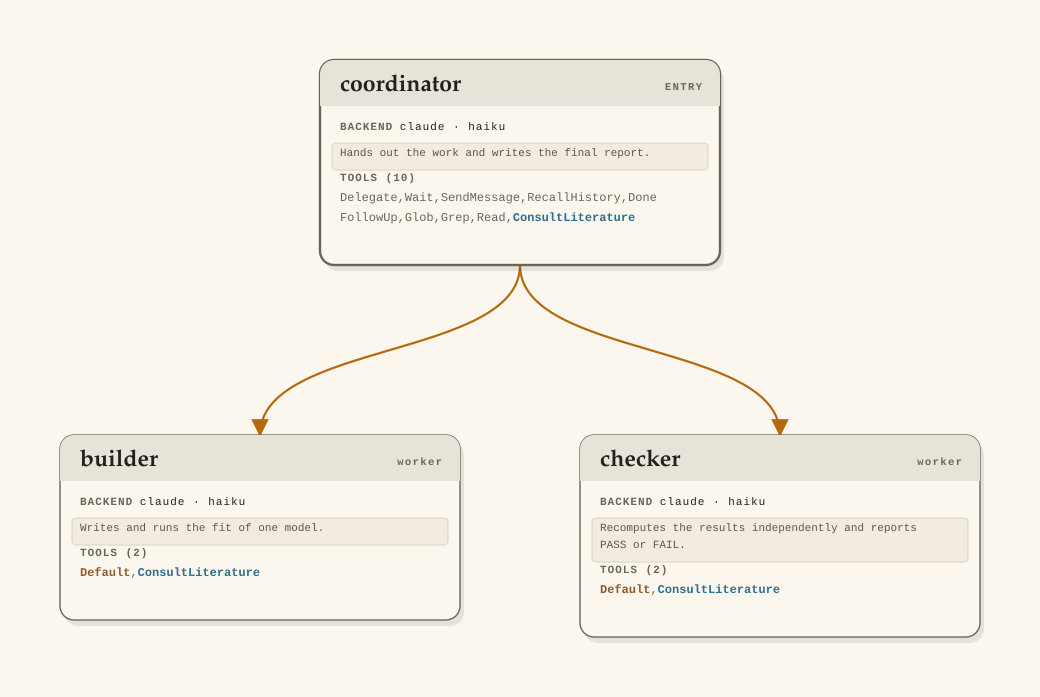

In [9]:
team = Graph(nodes={"coordinator": coordinator,
                    "builder":     builder,
                    "checker":     checker},
             edges=(Edge("coordinator", "builder"),   # who may hand work to whom
                    Edge("coordinator", "checker")),
             entry="coordinator")

display(SVG(filename=AgenticRun("car_team", graph=team).render_architecture()))

## Delegate or hand off

An edge says that one agent may pass work to another. There are two ways to do it:

<center><img src="../figures/adda_delegate_vs_handoff.png" title="Delegate or hand off" width="85%"></center>

| | delegate, `Edge(a, b)` | hand off, `Edge(a, b, handoff=True)` |
|---|---|---|
| what `a` gives `b` | a task | the whole job |
| what comes back to `a` | `b`'s report | nothing: `a` stops |
| who goes on | `a`, with the report | `b` |

Delegating is a professor asking a student for one result. Handing off is a relay race: the baton moves on. Our team only delegates, so the coordinator holds the job from start to end.

## Delegating, one after the other or at the same time

The coordinator hands out work with the tool `Delegate`, which `adda` gives to every node with an outgoing edge:

* `wait=True`: the coordinator waits for the report before it goes on
* `wait=False`: the work starts and the coordinator goes on; `Wait` collects the reports

M1 and M2 do not depend on each other, so the builder fits them **at the same time**. The check needs both, so it comes after.

## The limits of a run

| limit | setting | at the limit |
|---|---|---|
| time | `budget` (seconds) | no new delegations from 90%; at 100% the agents save what they have, and the run closes |
| tokens | `token_budget` (tokens the agents write) | as for time |
| cost | `budget_usd` (dollars) | the run stops |
| memory | `mem_cap` (for the work of each agent) | `adda` stops the work that goes over |
| evaluations | `eval_budget` | only reminders to the agents |

The evaluation budget is a reminder, not a limit. A hard limit goes in a tool, as `Measure` refused a 31st measurement in Lecture 19.

**Note.** `budget`, `budget_usd` and `eval_budget` are arguments of `AgenticRun`. `token_budget` and `mem_cap` go, for now, in a `config.yaml` file in the study folder.

## Running the study, twice

The decisions are ours, so two runs should give the **same numbers**. We run the study twice, each run in its own copy of the folder.

In [10]:
def run_team(study):
    """Run the team on a copy of car_team/ in `study`, unless it already ran; return the final report."""
    if not (study / "REPORT.md").exists():            # the agents run only once
        shutil.copytree("car_team", study, dirs_exist_ok=True)
        run = AgenticRun(study, graph=team,
                         budget=1200,                 # seconds
                         budget_usd=0.5,              # dollars
                         runtime=LEAN,                # as in Lecture 19 (first cell)
                         interactive=False,           # nobody answers questions during the run
                         review_statement=False)
        report = run.execute()                        # runs the team, and returns its final report
        (study / "REPORT.md").write_text(str(report))
    return (study / "REPORT.md").read_text()

In [11]:
display(Markdown(run_team(Path("car_team_run1"))))

Both models were fitted per PROBLEM_STATEMENT.md and independently rechecked by the checker. The checker's recomputation matches both CSVs to about 2e-16 relative, well inside the 1e-9 tolerance.

Results (split 37 train / 13 test):
- M1: a = 1.556792744461828, b = 0.1003596848656863, s = 27.98303080695783, coverage = 0.8462 (11/13), nll = 4.976149641475804. Check: PASS.
- M2: a = 1.3804030477145803, b = 0.10323542514078464, c = 0.5532310661868638, coverage = 0.8462 (11/13), nll = 4.503770939937342. Check: PASS.

Files are in workspace/results/: fit_M1.py, M1.csv, fit_M2.py, M2.csv, check.md. Both CSVs have exactly the required columns and one row each. Evaluations used: 0.

Caveats:
1. The checker parsed fit_M1.py and fit_M2.py with ast only and did not run them, so it is not verified that the scripts execute from scratch. The builders did run them, and the M1 and M2 builder outputs agree with the checker's recomputation.
2. The M2 builder overwrote an existing fit_M2.py and M2.csv, and the checker overwrote check.md. The current files are the ones these agents wrote this run.
3. Coverage is 11/13 for both models on only 13 test points, so it is a coarse estimate.

Falsification outcome: no separate falsification was run. The checker's independent recomputation is the only cross-check. Remaining uncertainty is the unrun scripts in caveat 1.

In [12]:
display(Markdown(run_team(Path("car_team_run2"))))

Both models were fitted per PROBLEM_STATEMENT.md (split 37 train / 13 test, random_state=1987), and the checker independently recomputed both with PASS.

Results (workspace/results/):
- M1: a=1.556793, b=0.100360, s=27.983031, coverage=0.846154 (11/13), nll=4.976150, n_train=37, n_test=13
- M2: a=1.380403, b=0.103235, c=0.553231, coverage=0.846154 (11/13), nll=4.503771, n_train=37, n_test=13

Checks (D003): M1 PASS and M2 PASS. All recomputed values match the files to rel. 2e-16. Both CSVs have exactly the required header and one row. fit_M1.py and fit_M2.py are present. The M2 fit follows the spec literally.

Note: the builder flagged that M2's mean a*x+b*x^2 is inconsistent with the y/x regression. It is not: y/x = a + b*x implies y = a*x + b*x^2, so the mean is consistent. No decisions were changed. 0 ground-truth evaluations were used; this is an analytic study with no evaluator. Remaining uncertainty: n_test=13 is small, so coverage (11/13) and nll are noisy. The two models share the same coverage on this split.

## The viewer

`adda` has a viewer, a web page that shows a run while it works and after it ends. One cell starts it and gives a link, and the notebook goes on.

In [13]:
viewer.start("car_team_run1", port=8799) # returns at once, with the link to the viewer

<adda viewer running at http://127.0.0.1:8799/session?token=BTA9GVXUsnCM9bBclxZ0qJMjFsUqeYDu>

<center><img src="../figures/adda_viewer_timeline.png" title="Run 1 in the adda viewer" width="75%"></center>

Run 1. The header gives the status of the run, its time against the budget, its cost and its delegations. In the Timeline, each card is placed at the time it ran, and cards side by side ran at the same time. X001 is the coordinator holding the job; each D card is one delegation.

## Questions from the agents

The coordinator lists the tool `FollowUp`, to ask **us** a question. With `interactive=True`, the run waits for our answer:

```python
viewer.start("car_team_ask")                                       # the question appears in a banner of the viewer
AgenticRun("car_team_ask", graph=team, interactive=True).execute() # the run waits for our answer
```

* The run waits up to 10 minutes (`runtime={"followup_wait_s": 600}`). Without an answer, the agent goes on with its own judgment.
* We answer in the viewer (or in the terminal, when the run is started from one).
* Our two runs used `interactive=False`, so they did not wait for anyone. Every decision was in the statement.

## The results of the two runs

In [14]:
rows = []
for run in ["car_team_run1", "car_team_run2"]:
    for model in ["M1", "M2"]:
        rows.append(pd.read_csv(f"{run}/workspace/results/{model}.csv").assign(run=run))
results = pd.concat(rows).set_index(["run", "model"])
results

a         b  sd_parameter  coverage       nll  \
run           model                                                         
car_team_run1 M1     1.556793  0.100360     27.983031  0.846154  4.976150   
              M2     1.380403  0.103235      0.553231  0.846154  4.503771   
car_team_run2 M1     1.556793  0.100360     27.983031  0.846154  4.976150   
              M2     1.380403  0.103235      0.553231  0.846154  4.503771   

                     n_train  n_test  
run           model                   
car_team_run1 M1          37      13  
              M2          37      13  
car_team_run2 M1          37      13  
              M2          37      13

## M1 or M2 on the test stops

Both models cover 11 of the 13 test stops, and M2 has the lower `nll`: its band widens with the speed, as the stops spread.

In [15]:
# @title Figure code: the 95% bands of M1 and M2, and the test stops (optional)
def plot_models(results, test):
    x = np.linspace(3, 82, 200)
    fig, ax = plt.subplots(figsize=(6, 4))
    for model, color in [("M1", "tab:orange"), ("M2", "b")]:
        r = results.loc[("car_team_run1", model)]
        mu = r["a"] * x + r["b"] * x**2
        sd = r["sd_parameter"] * (x if model == "M2" else np.ones_like(x))
        ax.fill_between(x, mu - 1.96 * sd, mu + 1.96 * sd, color=color, alpha=0.25, lw=0, label=model)
    ax.scatter(x_stops.loc[test, "x"], y_stops.loc[test, "y"], s=38, color="r", marker="x", linewidths=1.8, zorder=3)
    ax.set_xlabel("$x$ (m/s)", fontsize=20); ax.set_ylabel("$y$ (m)", fontsize=20)
    ax.legend(loc="upper left", frameon=False, fontsize=15)
    plt.show()

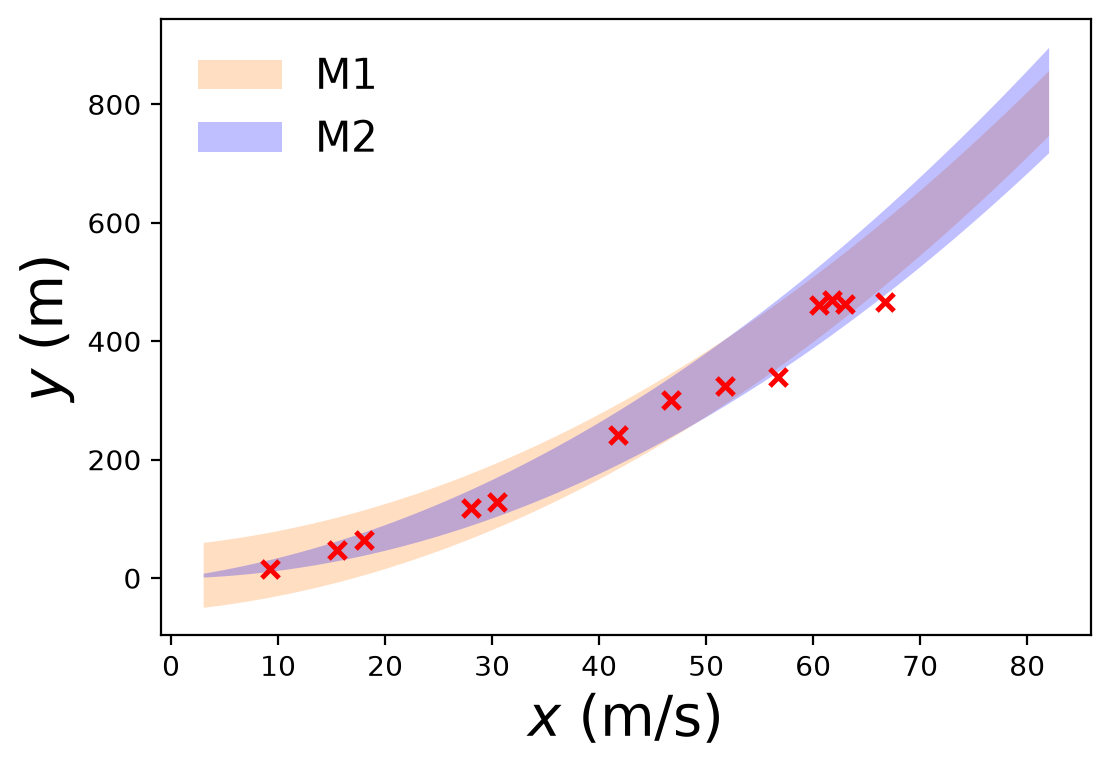

In [16]:
train, test = train_test_split(x_stops.index, train_size=0.75, random_state=1987) # the split of the statement
plot_models(results, test)

## A check that fails

* A FAIL of the checker, or of our own check, points at a **decision** that was missing or ambiguous. Our statement, for example, does not say whether a stop exactly on the edge of the band counts as inside.
* Fix the **statement** (or the prompt), not the output, and run again. Here, "a stop is inside the band when |y - mean| <= 1.96 standard deviation".
* Report the correction: which decision you added, and why.

A result corrected by hand cannot be reproduced by running the notebook again.

## Passing the job on

An edge comes in two kinds:

| Edge | What it lets the first agent do |
|---|---|
| `Edge(a, b)` | give `b` a task, and get its report back (our team today) |
| `Edge(a, b, handoff=True)` | pass `b` the whole job: `b` goes on from there, and `a` stops |

Only the agent that holds the job can pass it on, or call `Done`.

In [17]:
doe       = Agent(model="haiku", tools={"Default"}, description="Chooses the experiments.",
                  system_prompt="Choose the experiments, then hand the job to data.")
data      = Agent(model="haiku", tools={"Default"}, description="Runs the experiments.",
                  system_prompt="Run the experiments, then hand the job to surrogate.")
surrogate = Agent(model="haiku", tools={"Default"}, description="Fits a surrogate.",
                  system_prompt="Fit a surrogate, then hand the job to optimizer.")
optimizer = Agent(model="haiku", tools={"Default"}, description="Optimizes on the surrogate.",
                  system_prompt="Optimize on the surrogate, then hand the job to critic.")
critic    = Agent(model="haiku", tools={"Default", "Done"}, description="Checks the work.",
                  system_prompt="Check the work. Call Done if it holds, or hand the job back to the stage that went wrong.")

pipeline = Graph(nodes={"doe": doe, "data": data, "surrogate": surrogate, "optimizer": optimizer, "critic": critic},
                 edges=(Edge("doe",       "data",      handoff=True),  # the job moves forward
                        Edge("data",      "surrogate", handoff=True),
                        Edge("surrogate", "optimizer", handoff=True),
                        Edge("optimizer", "critic",    handoff=True),
                        Edge("critic",    "doe",       handoff=True),  # the critic can send it back
                        Edge("critic",    "data",      handoff=True),
                        Edge("critic",    "surrogate", handoff=True),
                        Edge("critic",    "optimizer", handoff=True)),
                 entry="doe")

<center><img src="../figures/adda_pipeline_handoffs.png" title="A pipeline with a critic" width="80%"></center>

Every edge is a handoff. The job starts at `doe` and moves forward one stage at a time. Only the `critic` holds `Done`: it closes the run, or sends the job back to the stage it judges wrong. `adda` refuses a graph in which no handoff path leads from the entry to an agent that holds `Done`.

## Toward the Final Project

Tasks 4 and 5 of the Final Project use `adda` as this lecture did:

* a **table of decisions** in your report, before any prompt
* a **team** that you define, with every agent on Haiku
* a **notebook that runs the team**, which we will rerun several times when grading
* **checks you make yourself**, and every correction you made to the statement

The agents implement. The interpretation of the results is yours.

### In-class Exercise 1

Add a third model to the table of decisions, **M3**: the same mean, and a standard deviation proportional to the mean, $c\,\mu(x)$. Write it so that only one implementation is possible, and run the team again in a new folder.

1. Which decisions did you have to add?
2. Does the checker agree with the builder?

### In-class Exercise 2

Copy `car_team` to `car_team_ask`, and delete the row **Split** from its table of decisions. Start the viewer, run the team with `interactive=True`, and answer in the viewer if the coordinator asks.

1. Did the coordinator ask, and what?
2. What did the team do with your answer, or without one?

## Summary of today

1. **Decide before you prompt**: a table of decisions in the statement, so that the agents implement and do not interpret.
2. **Small tasks with a clear result**: one model per delegation, a file with fixed columns.
3. **Independent work runs in parallel**: `wait=False`, then `Wait`.
4. **A checker with a different job** recomputes the results without the builder's code. When a check fails, fix the statement, not the output.
5. **Set the limits** of time and cost in `AgenticRun`. A hard limit on evaluations goes in a tool.
6. **Run it again**: with every decision fixed, two runs give the same numbers.
7. **Two kinds of edge**: a delegation returns a report, a handoff passes the job on.

## Field guide: what this lecture adds

### Good practices

**7. Work with an AI coding agent**
- **Check against something you know**, not against "the code runs": e.g. the normal equations, or "the training error cannot increase with the degree".
- **Pin every choice that can change a number you report**, including the randomness of the split. Read the agent's **Assumptions** and **open its files**: they may contain things that your prompt should have defined.
- **A team of agents is a graph**: each node is an agent with its own prompt, tools and model, and each edge says who may hand work to whom. Start with one node.
- **Decide before you prompt**: a table of decisions in the statement, so that the agents implement and do not interpret.
- **Give the checker a different job from the builder**: it recomputes the results without the builder's code.
- **Fix the statement, not the output**, and run again: a result corrected by hand is not reproduced by the notebook.

The whole [field guide](https://github.com/bessagroup/3dasm_course/blob/main/FIELD_GUIDE.md) collects the key concepts and good practices of every lecture.

### See you next class

Have fun!